In [9]:
import pandas as pd

In [10]:
import numpy as np

In [11]:
import matplotlib.pyplot as plt

In [13]:
%pip install seaborn

In [14]:
import seaborn as sns

In [23]:
df = pd.read_csv("cleaned_sales_data.csv", encoding="latin1")

In [24]:
df.head(5)

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,...,product_id,category,sub-category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority
0,42433,AG-2011-2040,2011-01-01,2011-01-06,Standard Class,TB-11280,Toby Braunhardt,Consumer,Constantine,Constantine,...,OFF-TEN-10000025,Office Supplies,Storage,"Tenex Lockers, Blue",408.300,2,0.0,106.140,35.46,Medium
1,22253,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,...,OFF-SU-10000618,Office Supplies,Supplies,"Acme Trimmer, High Speed",120.366,3,0.1,36.036,9.72,Medium
2,48883,HU-2011-1220,2011-01-01,2011-01-05,Second Class,AT-735,Annie Thurman,Consumer,Budapest,Budapest,...,OFF-TEN-10001585,Office Supplies,Storage,"Tenex Box, Single Width",66.120,4,0.0,29.640,8.17,High
3,11731,IT-2011-3647632,2011-01-01,2011-01-05,Second Class,EM-14140,Eugene Moren,Home Office,Stockholm,Stockholm,...,OFF-PA-10001492,Office Supplies,Paper,"Enermax Note Cards, Premium",44.865,3,0.5,-26.055,4.82,High
4,22255,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,...,FUR-FU-10003447,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",113.670,5,0.1,37.770,4.70,Medium


In [25]:
df.shape

(51290, 23)

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 23 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   row_id          51290 non-null  int64  
 1   order_id        51290 non-null  str    
 2   order_date      51290 non-null  str    
 3   ship_date       51290 non-null  str    
 4   ship_mode       51290 non-null  str    
 5   customer_id     51290 non-null  str    
 6   customer_name   51290 non-null  str    
 7   segment         51290 non-null  str    
 8   city            51290 non-null  str    
 9   state           51290 non-null  str    
 10  country         51290 non-null  str    
 11  market          51290 non-null  str    
 12  region          51290 non-null  str    
 13  product_id      51290 non-null  str    
 14  category        51290 non-null  str    
 15  sub-category    51290 non-null  str    
 16  product_name    51290 non-null  str    
 17  sales           51290 non-null  float64
 1

In [27]:
df.dtypes

row_id              int64
order_id              str
order_date            str
ship_date             str
ship_mode             str
customer_id           str
customer_name         str
segment               str
city                  str
state                 str
country               str
market                str
region                str
product_id            str
category              str
sub-category          str
product_name          str
sales             float64
quantity            int64
discount          float64
profit            float64
shipping_cost     float64
order_priority        str
dtype: object

In [28]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

In [29]:
df.dtypes

row_id                     int64
order_id                     str
order_date        datetime64[us]
ship_date         datetime64[us]
ship_mode                    str
customer_id                  str
customer_name                str
segment                      str
city                         str
state                        str
country                      str
market                       str
region                       str
product_id                   str
category                     str
sub-category                 str
product_name                 str
sales                    float64
quantity                   int64
discount                 float64
profit                   float64
shipping_cost            float64
order_priority               str
dtype: object

In [ ]:
#Understanding the Distribution of Sales

In [30]:
df["sales"].describe()

count    51290.000000
mean       246.490581
std        487.565361
min          0.444000
25%         30.758625
50%         85.053000
75%        251.053200
max      22638.480000
Name: sales, dtype: float64

In [31]:
df["sales"].median()

np.float64(85.053)

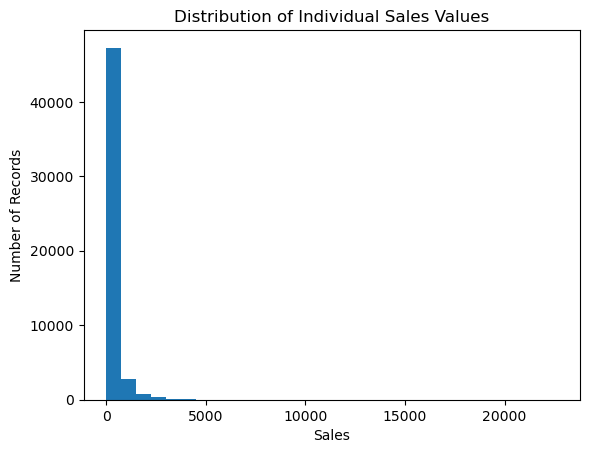

In [32]:
plt.hist(df["sales"], bins=30)
plt.xlabel("Sales")
plt.ylabel("Number of Records")
plt.title("Distribution of Individual Sales Values")
plt.show()

In [ ]:
#Relationship Between Sales and Profit

In [33]:
df["sales"].corr(df["profit"])

np.float64(0.4849181126194453)

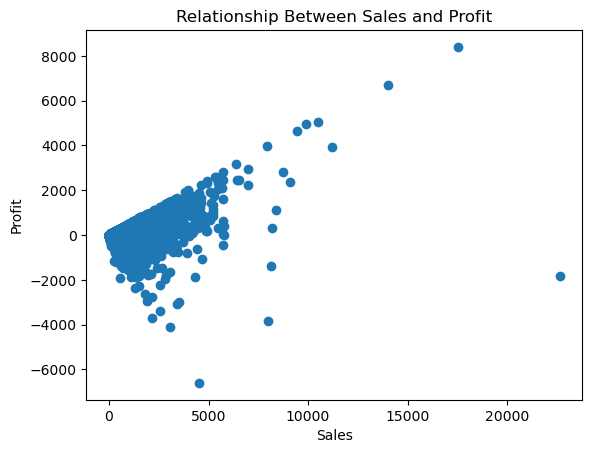

In [34]:
plt.scatter(df["sales"], df["profit"])
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.title("Relationship Between Sales and Profit")
plt.show()

In [ ]:
#Relationship Between Order Quantity and Profit

In [35]:
df.groupby("quantity")["profit"].mean()

quantity
1       7.254517
2      16.360682
3      24.323615
4      34.724614
5      46.477984
6      41.426103
7      66.821232
8      61.538104
9      74.818913
10     62.280717
11     81.550999
12     29.059935
13    155.497354
14    106.119887
Name: profit, dtype: float64

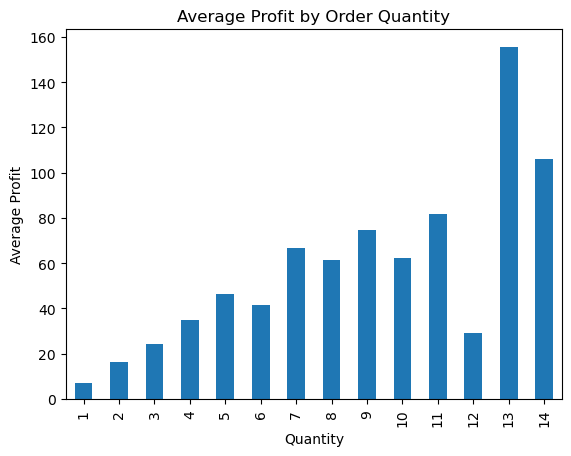

In [36]:
df.groupby("quantity")["profit"].mean().plot(kind="bar")

plt.xlabel("Quantity")
plt.ylabel("Average Profit")
plt.title("Average Profit by Order Quantity")
plt.show()

In [ ]:
#Order-to-Shipment Duration Analysis

In [43]:
(df["ship_date"] - df["order_date"]).dt.days.describe()

count    51290.000000
mean         3.969370
std          1.729437
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max          7.000000
dtype: float64

In [41]:
(df["ship_date"] - df["order_date"]).dt.days.median()

np.float64(4.0)

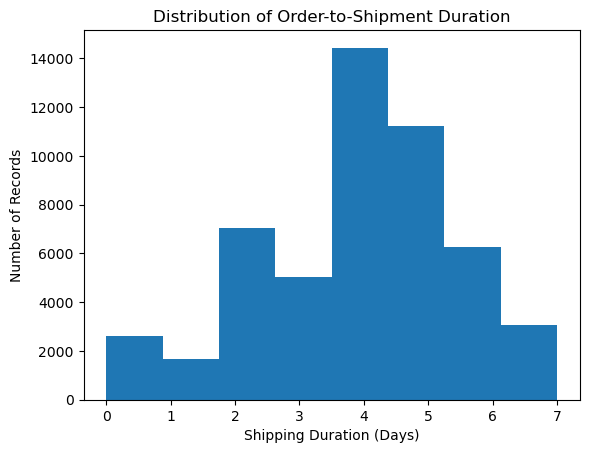

In [44]:
plt.hist((df["ship_date"] - df["order_date"]).dt.days, bins=8)

plt.xlabel("Shipping Duration (Days)")
plt.ylabel("Number of Records")
plt.title("Distribution of Order-to-Shipment Duration")
plt.show()

In [ ]:
#Sales Outlier Analysis

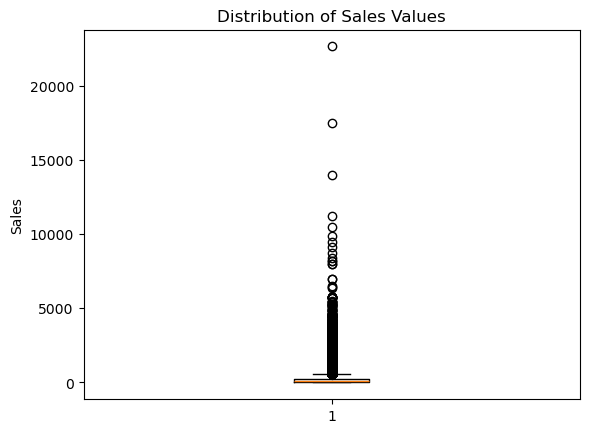

In [45]:
plt.boxplot(df["sales"])

plt.ylabel("Sales")
plt.title("Distribution of Sales Values")
plt.show()

In [ ]:
#Correlation Between Numerical Variables

In [46]:
df[["sales", "profit", "quantity", "discount", "shipping_cost"]].corr()

,sales,profit,quantity,discount,shipping_cost
sales,1.000000,0.484918,0.313577,-0.086722,0.768073
profit,0.484918,1.000000,0.104365,-0.316490,0.354441
quantity,0.313577,0.104365,1.000000,-0.019875,0.272649
discount,-0.086722,-0.316490,-0.019875,1.000000,-0.079056
shipping_cost,0.768073,0.354441,0.272649,-0.079056,1.000000


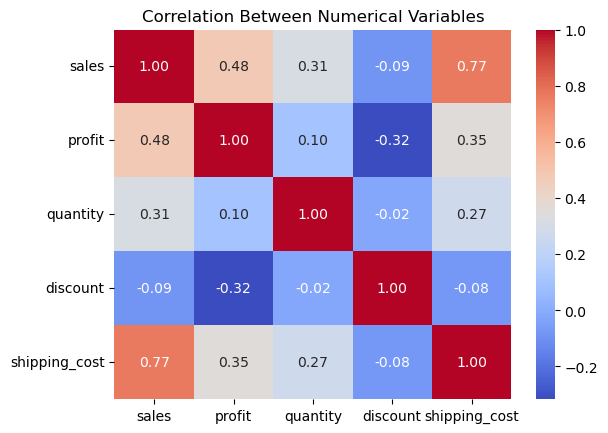

In [47]:
sns.heatmap(
    df[["sales", "profit", "quantity", "discount", "shipping_cost"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Numerical Variables")
plt.show()

In [ ]:
#How Profit Varies Across Different Discount Levels

In [48]:
df.groupby("discount")["profit"].mean()

discount
0.000      61.039514
0.002     125.762649
0.070     140.990022
0.100      63.683426
0.150      50.602409
0.170      38.317107
0.200      23.552594
0.202     -14.518847
0.250       4.043371
0.270      -4.317213
0.300     -57.899557
0.320     -88.560656
0.350    -116.144693
0.370     -78.462191
0.400     -45.246603
0.402    -109.908138
0.450     -41.610973
0.470     -42.982420
0.500     -97.140158
0.550    -315.067200
0.570    -526.129000
0.600     -81.732147
0.602    -213.279085
0.650    -365.997971
0.700    -104.339576
0.800    -122.203244
0.850   -1534.329000
Name: profit, dtype: float64

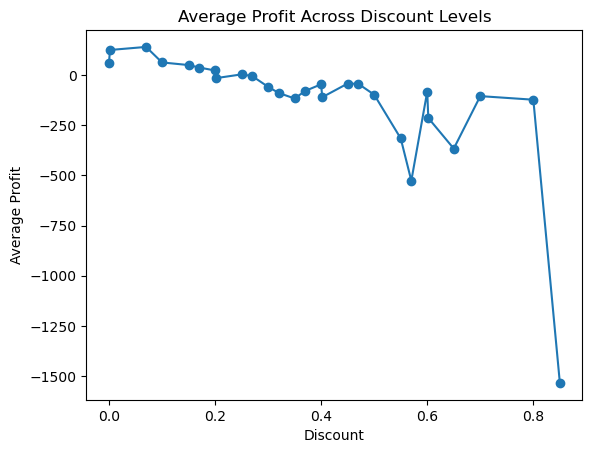

In [52]:
df.groupby("discount")["profit"].mean().plot(kind="line", marker="o")

plt.xlabel("Discount")
plt.ylabel("Average Profit")
plt.title("Average Profit Across Discount Levels")
plt.show()

In [ ]:
#Sales Distribution Across Customer Segments

In [53]:
df.groupby("segment")["sales"].describe()

,count,mean,std,min,25%,50%,75%,max
segment,,,,,,,,
Consumer,26518.0,245.416299,477.132518,0.444,30.6900,85.005,250.992,13999.96
Corporate,15429.0,247.890176,486.043062,0.556,31.0800,85.440,252.840,17499.95
Home Office,9343.0,247.228403,518.439396,0.990,30.3795,84.600,248.760,22638.48


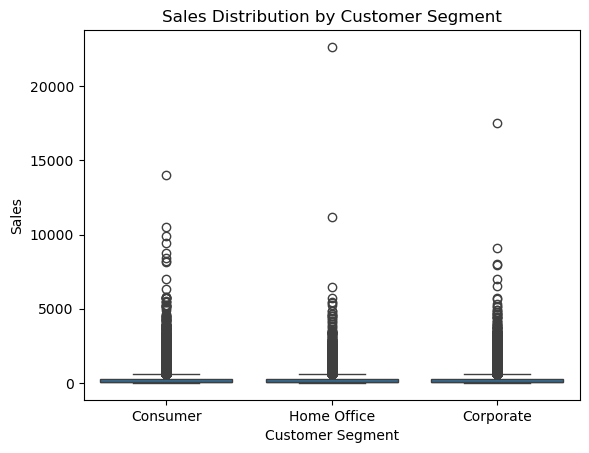

In [54]:
sns.boxplot(data=df, x="segment", y="sales")

plt.xlabel("Customer Segment")
plt.ylabel("Sales")
plt.title("Sales Distribution by Customer Segment")
plt.show()

In [ ]:
#Sales Distribution Across Product Categories

In [55]:
df.groupby("category")["sales"].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Furniture,9876.0,416.248905,553.066417,1.892,91.026,220.20,509.265,5759.964
Office Supplies,31273.0,121.097120,299.321405,0.444,20.340,46.38,105.240,9892.740
Technology,10141.0,467.858939,708.972701,0.990,117.150,260.34,554.850,22638.480


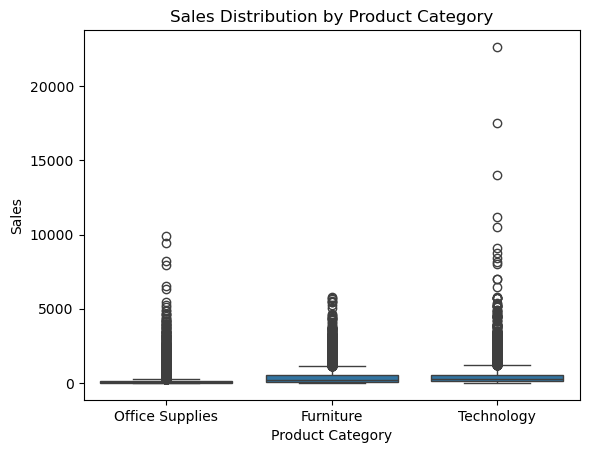

In [56]:
sns.boxplot(data=df, x="category", y="sales")

plt.xlabel("Product Category")
plt.ylabel("Sales")
plt.title("Sales Distribution by Product Category")
plt.show()

In [ ]:
#Monthly Sales Trends

In [58]:
df["month"] = df["order_date"].dt.to_period("M")

In [59]:
df[["order_date", "month"]].head()

,order_date,month
0,2011-01-01,2011-01
1,2011-01-01,2011-01
2,2011-01-01,2011-01
3,2011-01-01,2011-01
4,2011-01-01,2011-01


In [60]:
df.groupby("month")["sales"].mean()

month
2011-01    228.402977
2011-02    241.143272
2011-03    270.369884
2011-04    207.297454
2011-05    259.271795
2011-06    234.686347
2011-07    233.354382
2011-08    236.425389
2011-09    275.869254
2011-10    257.198016
2011-11    262.068953
2011-12    264.390922
2012-01    251.912282
2012-02    234.289550
2012-03    246.339533
2012-04    245.132830
2012-05    248.053442
2012-06    225.506777
2012-07    220.389659
2012-08    279.910381
2012-09    236.622376
2012-10    255.494798
2012-11    221.583847
2012-12    263.440005
2013-01    280.939221
2013-02    276.429174
2013-03    259.261136
2013-04    226.523970
2013-05    246.450865
2013-06    259.163145
2013-07    248.571840
2013-08    226.413862
2013-09    223.911561
2013-10    266.733312
2013-11    234.329173
2013-12    253.092620
2014-01    262.819777
2014-02    244.493857
2014-03    246.349038
2014-04    230.991305
2014-05    224.611407
2014-06    229.870745
2014-07    237.999706
2014-08    272.608921
2014-09    238.432727
2014

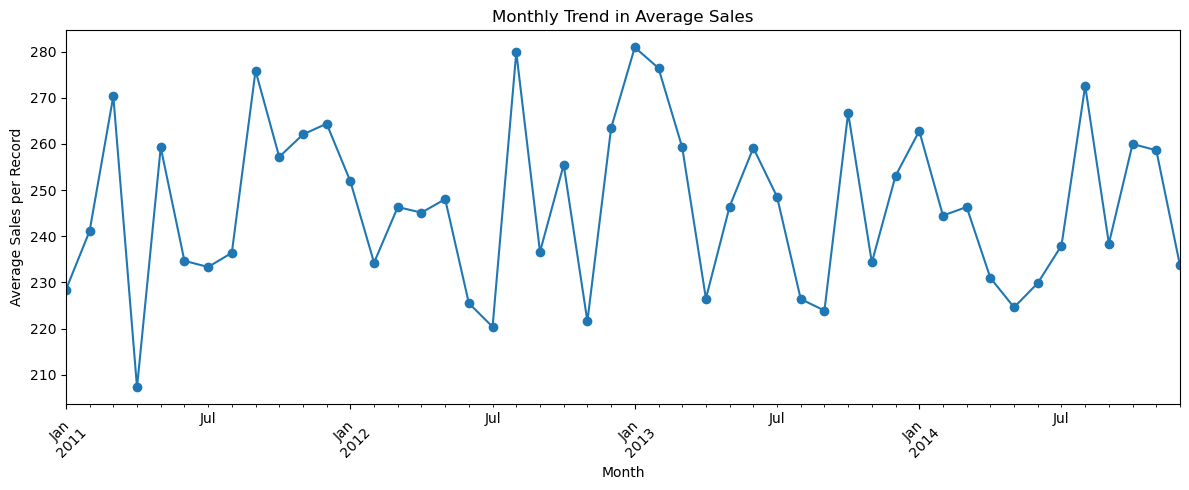

In [61]:
df.groupby("month")["sales"].mean().plot(kind="line", marker="o", figsize=(12, 5))

plt.xlabel("Month")
plt.ylabel("Average Sales per Record")
plt.title("Monthly Trend in Average Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Relationship Between Discount and Sales

In [62]:
df["discount"].corr(df["sales"])

np.float64(-0.0867218669718054)

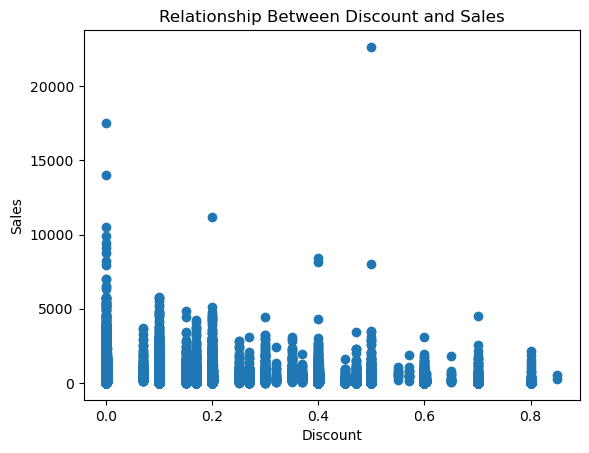

In [63]:
plt.scatter(df["discount"], df["sales"])
plt.xlabel("Discount")
plt.ylabel("Sales")
plt.title("Relationship Between Discount and Sales")
plt.show()

In [ ]:
#Which product subcategories have the most variable profit?

In [77]:
df.groupby("sub-category")["profit"].std().sort_values(ascending=False)

sub-category
Tables         402.973963
Copiers        365.093054
Machines       347.491558
Appliances     302.596743
Phones         251.666470
Bookcases      242.859457
Chairs         180.977823
Binders        153.960611
Accessories    126.787072
Storage         93.922868
Furnishings     56.166072
Supplies        44.851356
Paper           32.307508
Art             32.199936
Envelopes       31.608325
Labels          16.190922
Fasteners       14.180009
Name: profit, dtype: float64

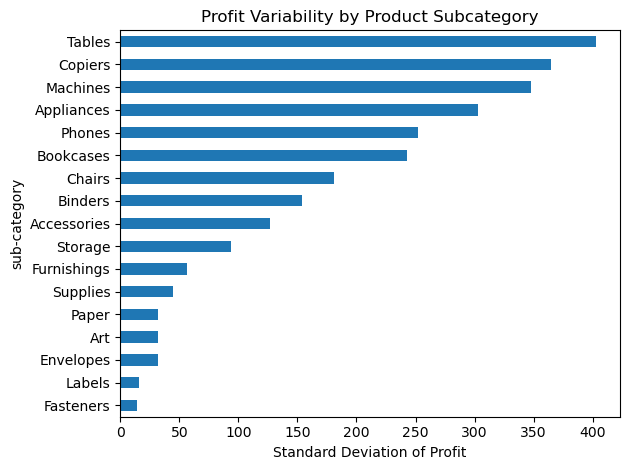

In [79]:
df.groupby("sub-category")["profit"].std().sort_values().plot(
    kind="barh", title="Profit Variability by Product Subcategory"
)

plt.xlabel("Standard Deviation of Profit")
plt.tight_layout()
plt.show()